# Notebook 1: ODE Simulation with kipetax

This notebook demonstrates how to simulate a reaction system using kipetax.
We use the classic A → B → C reaction from kipet Example 1.

**Reaction system:**
- A → B with rate k1 = 2.0
- B → C with rate k2 = 0.2

ODEs:
- dA/dt = -k1·A
- dB/dt = k1·A - k2·B
- dC/dt = k2·B

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import matplotlib.pyplot as plt
import kipetax

## Build the reaction model

In [2]:
# Create a ReactionModel instance
r1 = kipetax.ReactionModel('reaction-1')

# Add model parameters (fixed values for simulation)
k1 = r1.parameter('k1', value=2.0)
k2 = r1.parameter('k2', value=0.2)

# Declare components with initial conditions
A = r1.component('A', value=1.0)
B = r1.component('B', value=0.5)
C = r1.component('C', value=0.0)

# Define ODEs using natural Python expressions
r1.add_ode('A', -k1 * A)
r1.add_ode('B',  k1 * A - k2 * B)
r1.add_ode('C',  k2 * B)

# Set the simulation time span
r1.set_time(10.0)

# Set discretization parameters
r1.set_discretization(nfe=50, ncp=3)

print("Model built successfully")

Model built successfully


## Run the simulation

In [3]:
r1.simulate()
ro = r1.results_dict['simulator']
print(f"Simulation status: {ro.status}")

Simulation complete: status=optimal
Simulation status: optimal


## Plot the results

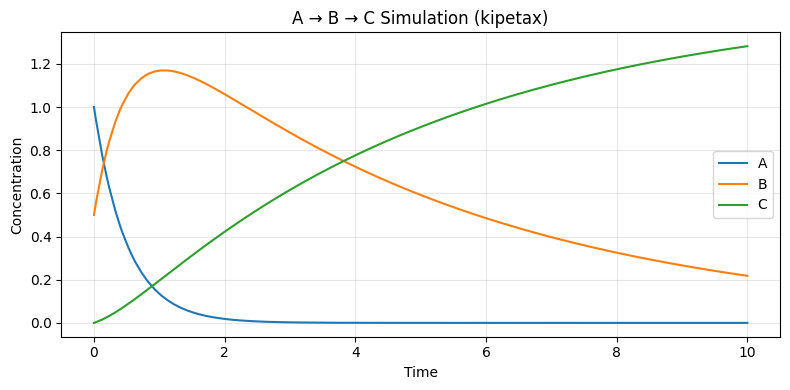


Final concentrations at t=10.0:
  A: 0.0000
  B: 0.2180
  C: 1.2820


In [4]:
Z = ro.Z  # Concentration profiles DataFrame: index=time, columns=components

fig, ax = plt.subplots(figsize=(8, 4))
for comp in Z.columns:
    ax.plot(Z.index, Z[comp], label=comp)

ax.set_xlabel('Time')
ax.set_ylabel('Concentration')
ax.set_title('A → B → C Simulation (kipetax)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nFinal concentrations at t={Z.index[-1]:.1f}:")
for comp, val in Z.iloc[-1].items():
    print(f"  {comp}: {val:.4f}")

## Verify mass balance

Total concentration A + B + C should be conserved (= 1.0 + 0.5 + 0.0 = 1.5).

In [5]:
total = Z.sum(axis=1)
print(f"Initial total: {total.iloc[0]:.4f}")
print(f"Final total:   {total.iloc[-1]:.4f}")
print(f"Max deviation: {abs(total - total.iloc[0]).max():.2e}")
assert abs(total - 1.5).max() < 0.01, "Mass balance violated!"
print("\nMass balance verified ✓")

Initial total: 1.5000
Final total:   1.5000
Max deviation: 6.00e-15

Mass balance verified ✓


## Compare with analytical solution

For the simple A → B → C system with k1=2, k2=0.2:
- A(t) = A0 · exp(-k1·t)
- B(t) analytically from integrating factor

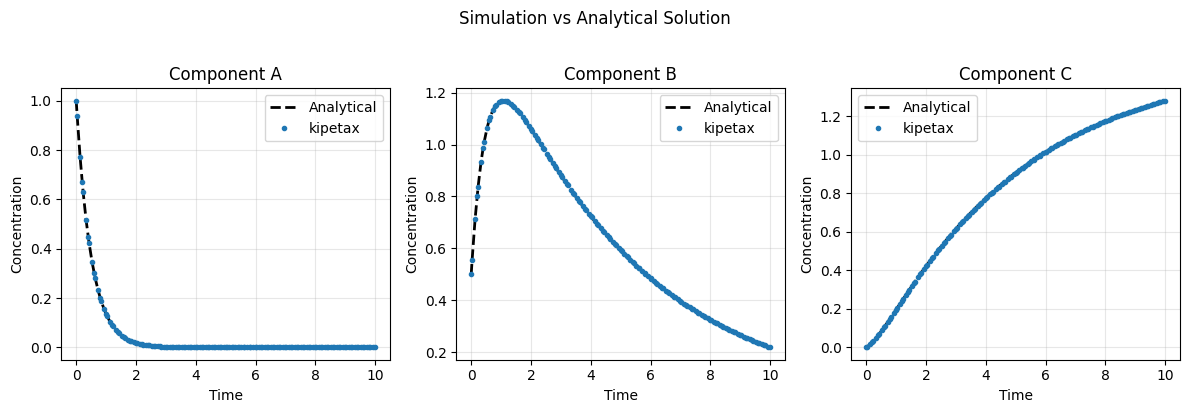

Max error vs analytical: 2.43e-05


In [6]:
A0, B0 = 1.0, 0.5
k1_val, k2_val = 2.0, 0.2
t = np.array(Z.index)

A_exact = A0 * np.exp(-k1_val * t)
B_exact = (A0 * k1_val / (k1_val - k2_val)) * (np.exp(-k2_val * t) - np.exp(-k1_val * t)) \
          + B0 * np.exp(-k2_val * t)
C_exact = A0 + B0 - A_exact - B_exact

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, comp, exact in zip(axes, ['A', 'B', 'C'], [A_exact, B_exact, C_exact]):
    ax.plot(t, exact, 'k--', label='Analytical', linewidth=2)
    ax.plot(Z.index, Z[comp], 'o', markersize=3, label='kipetax')
    ax.set_xlabel('Time')
    ax.set_ylabel('Concentration')
    ax.set_title(f'Component {comp}')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle('Simulation vs Analytical Solution', y=1.02)
plt.tight_layout()
plt.show()

max_err = max(
    np.abs(np.interp(t, t, A_exact) - Z['A'].values).max(),
    np.abs(np.interp(t, t, B_exact) - Z['B'].values).max(),
)
print(f"Max error vs analytical: {max_err:.2e}")